# Study 9: beta sensitivity — free vs fixed speaker rationality

The free-beta fit lands at a LOW speaker rationality (beta ~ 0.9), giving a nearly-flat
coherence field. This notebook asks: **how much worse is the fit if we PIN beta at the design
value 3, or at the old (unlucky-run) value 16?** If pinning beta high costs little log Z / ELBO,
beta is weakly identified on study 9 (which has only generic utterances). If it costs a lot, the
data genuinely prefer the low value.

For each beta we fit `(length_scale, mu_0, sigma)` with the per-feature linking shapes profiled
out (beta held fixed), fitted length scale, and compare:
- **summed log Z** at the posterior-median theta (deterministic likelihood — the robust metric)
- **VBMC ELBO** (model evidence; same # free params across the fixed-beta fits, so directly comparable)


In [1]:
import os
os.environ.setdefault("JAX_ENABLE_X64", "1")
import sys; sys.path.insert(0, ".")
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import inference as inf

RESULTS_DIR = 'results/study9-fit'
DATA_CSV    = '../../data/study9_prereg.csv'
MAX_EVALS   = 400
SEED        = 37

geom = inf.load_geometry()
J = geom['J']
responses_cond, _ = inf.load_responses(DATA_CSV)
emp_cond = {c: np.array(responses_cond[c]).mean(0) for c in inf.CONDITIONS}
print("conditions:", inf.CONDITIONS, " J =", J)


conditions: ['physical', 'diet', 'personality', 'heterogeneous']  J = 15


## 1. Fit helpers

`fit_beta_fixed(beta_val)` pins beta by temporarily setting `inf.BETA_SPEAKER` (the objective
closure reads it at call time) and fitting with `fit_beta=False`. Cached to
`fitted-feature-shapes-beta<val>.npz` — delete to refit.

In [2]:
SAMPLE_KEYS = ('ls_samples', 'mu0_samples', 'sigma_samples', 'beta_samples')

def _load_or_none(path):
    if not os.path.exists(path): return None
    z = np.load(path, allow_pickle=True)
    fit = {k: z[k] for k in SAMPLE_KEYS}; fit.update(json.loads(str(z['meta'])))
    return fit

def fit_beta_fixed(beta_val, max_evals=MAX_EVALS):
    "Fit (ls, mu_0, sigma) with beta PINNED at beta_val (fitted ls, free shapes)."
    tag = str(beta_val).replace('.', 'p')
    path = os.path.join(RESULTS_DIR, f'fitted-feature-shapes-beta{tag}.npz')
    cached = _load_or_none(path)
    if cached is not None:
        print(f"loaded cached beta={beta_val}: {path}")
        return cached
    orig = inf.BETA_SPEAKER
    inf.BETA_SPEAKER = float(beta_val)
    try:
        fit = inf.run_vbmc(geom, responses_cond, fit_beta=False, max_evals=max_evals,
                           n_posterior_samples=4000, seed=SEED, verbose=False)
    finally:
        inf.BETA_SPEAKER = orig
    fit['beta_samples'] = np.full(fit['ls_samples'].shape[0], float(beta_val))
    np.savez_compressed(path, **{k: fit[k] for k in SAMPLE_KEYS},
                        meta=json.dumps({k: fit[k] for k in ('elbo','func_count','convergence_status','runtime_s')}))
    print(f"saved beta={beta_val}: {path}  (elbo={fit['elbo']:.1f}, conv={fit['convergence_status']})")
    return fit

def median_theta(fit):
    return (float(np.median(fit['ls_samples'])), float(np.median(fit['mu0_samples'])),
            float(np.median(fit['sigma_samples'])), float(np.median(fit['beta_samples'])))

def summed_logZ(theta):
    ls, mu, sig, beta = theta
    return inf.total_log_lik_free_shapes(geom, responses_cond, ls, mu, sig, beta_speaker=beta)


## 2. Load the free-beta reference + fit beta pinned at 3 and 16

In [3]:
# free-beta reference (the main study-9 fit)
free = _load_or_none(os.path.join(RESULTS_DIR, 'fitted-feature-shapes.npz'))
assert free is not None, "run study 9 first (run_parameter_estimation.py study9)"

fits = {
    'free':      free,
    'beta=3':    fit_beta_fixed(3.0),
    'beta=16':   fit_beta_fixed(16.0),
}


loaded cached beta=3.0: results/study9-fit/fitted-feature-shapes-beta3p0.npz
loaded cached beta=16.0: results/study9-fit/fitted-feature-shapes-beta16p0.npz


## 3. Comparison table

`logZ` is the deterministic summed Laplace log Z at each fit's posterior-median theta (robust,
independent of VBMC convergence). `elbo` is VBMC's model-evidence estimate. Deltas are vs the
free-beta fit.

In [4]:
rows = []
llf = summed_logZ(median_theta(fits['free']))
for name, fit in fits.items():
    ls, mu, sig, beta = median_theta(fit)
    ll = summed_logZ((ls, mu, sig, beta))
    rows.append({'model': name, 'beta': round(beta,3), 'ls': round(ls,3),
                 'mu_0': round(mu,3), 'sigma': round(sig,3),
                 'logZ': round(ll,1), 'dLogZ_vs_free': round(ll-llf,1),
                 'elbo': round(fit['elbo'],1), 'dELBO_vs_free': round(fit['elbo']-fits['free']['elbo'],1),
                 'conv': fit['convergence_status']})
df = pd.DataFrame(rows).set_index('model')
print(df.to_string())
print("\nInterpretation: if pinning beta high (3, 16) costs little logZ/ELBO, beta is weakly")
print("identified on study 9. If it costs a lot, the data genuinely prefer the low free value.")


           beta     ls   mu_0  sigma   logZ  dLogZ_vs_free   elbo  dELBO_vs_free conv
model                                                                                
free      0.907  0.978  0.006  0.526  988.8            0.0  983.3            0.0   no
beta=3    3.000  1.355 -0.493  0.479  972.1          -16.7  976.5           -6.9   no
beta=16  16.000  1.243 -0.385  0.335  983.4           -5.3  976.8           -6.6   no

Interpretation: if pinning beta high (3, 16) costs little logZ/ELBO, beta is weakly
identified on study 9. If it costs a lot, the data genuinely prefer the low free value.


## 4. Beta profile: log Z vs beta at the free fit's (ls, mu_0, sigma)

A continuous slice showing the log Z landscape along beta. The peak location and how sharply it
falls off tell you how strongly the data constrain beta.

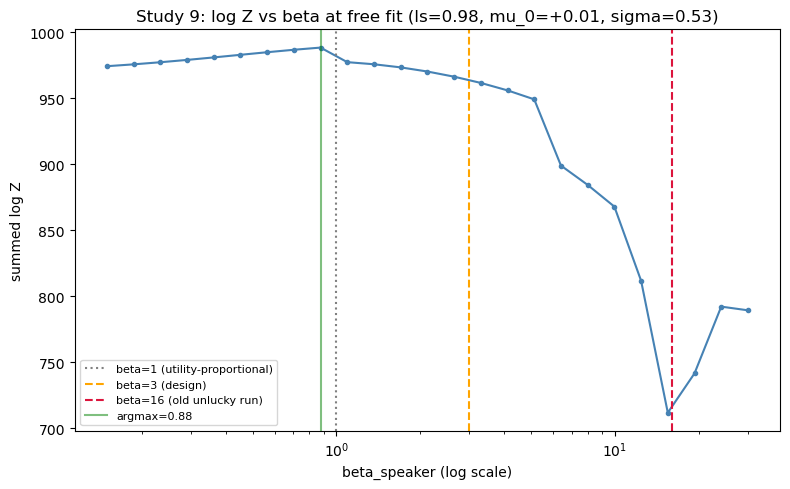

log Z at beta=argmax: 988.5


  beta=  0.9: logZ=988.7  (cost vs max: +0.2)


  beta=  1.0: logZ=977.9  (cost vs max: -10.6)


  beta=  3.0: logZ=963.9  (cost vs max: -24.7)


  beta= 16.0: logZ=709.0  (cost vs max: -279.5)


In [5]:
ls0, mu0, sig0, _ = median_theta(fits['free'])
beta_grid = np.geomspace(0.15, 30.0, 25)
ll_slice = np.array([inf.total_log_lik_free_shapes(geom, responses_cond, ls0, mu0, sig0, beta_speaker=float(b))
                     for b in beta_grid])

fig, ax = plt.subplots(figsize=(8, 5))
ax.plot(beta_grid, ll_slice, '-o', ms=3, color='steelblue')
ax.axvline(1.0,  color='gray', ls=':',  label='beta=1 (utility-proportional)')
ax.axvline(3.0,  color='orange', ls='--', label='beta=3 (design)')
ax.axvline(16.0, color='crimson', ls='--', label='beta=16 (old unlucky run)')
ax.axvline(beta_grid[np.argmax(ll_slice)], color='green', ls='-', alpha=0.5,
           label=f'argmax={beta_grid[np.argmax(ll_slice)]:.2f}')
ax.set_xscale('log'); ax.set_xlabel('beta_speaker (log scale)'); ax.set_ylabel('summed log Z')
ax.set_title(f'Study 9: log Z vs beta at free fit (ls={ls0:.2f}, mu_0={mu0:+.2f}, sigma={sig0:.2f})')
ax.legend(fontsize=8)
plt.tight_layout(); plt.show()

print(f"log Z at beta=argmax: {ll_slice.max():.1f}")
for b in [0.9, 1.0, 3.0, 16.0]:
    ll = inf.total_log_lik_free_shapes(geom, responses_cond, ls0, mu0, sig0, beta_speaker=b)
    print(f"  beta={b:5.1f}: logZ={ll:.1f}  (cost vs max: {ll-ll_slice.max():+.1f})")


## 5. Coherence fields per condition, for each beta fit

For each fit (free beta ~0.9, beta=3, beta=16) the 2x2 per-condition GP coherence field over the
2d embedding, at that fit's posterior-median theta. This shows *how the field changes with beta*:
higher beta + the compensating (mu_0, sigma) produce a more dramatic-looking field, but it fits the
prevalence data worse (see the log Z / ELBO table above). Each panel's title reports
`r(field @ test, mean rating)`; a near-constant field reports 'r undefined'.


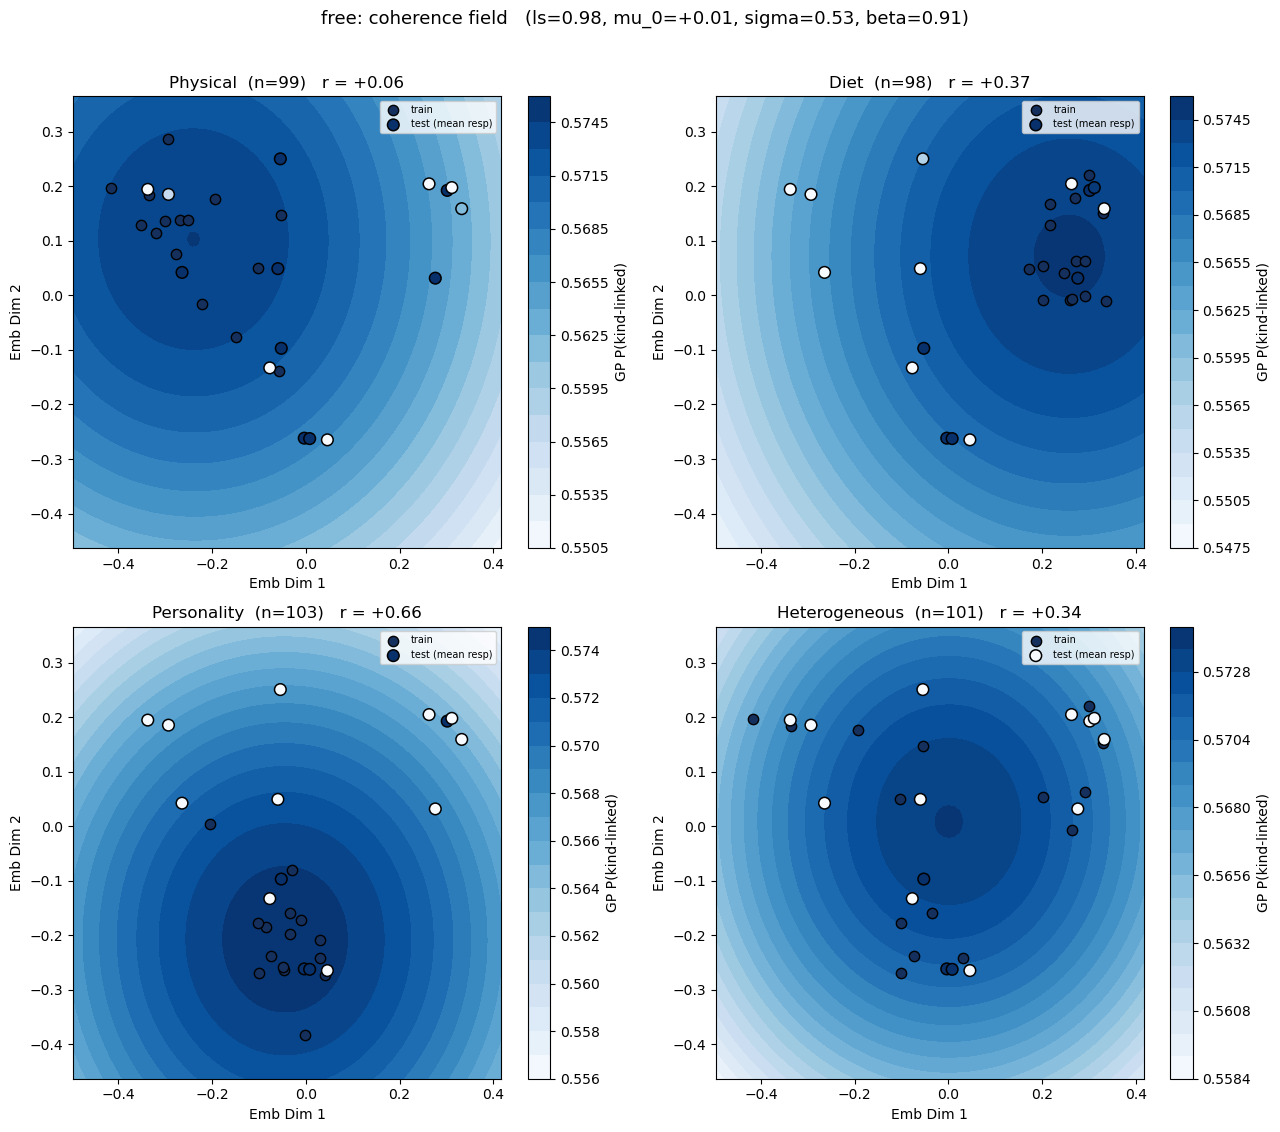

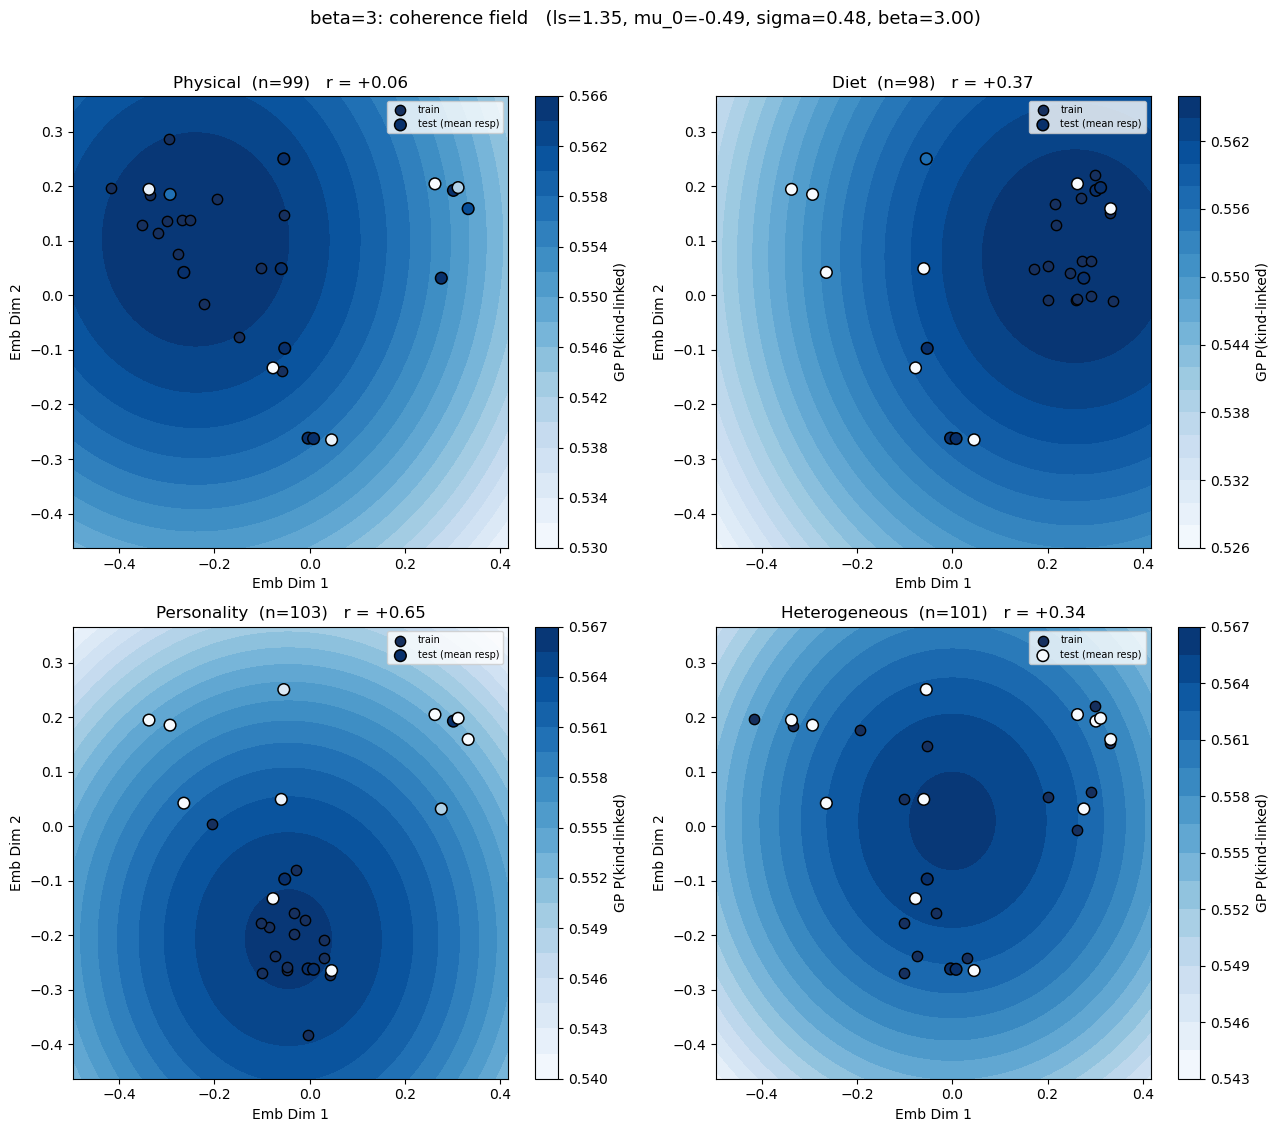

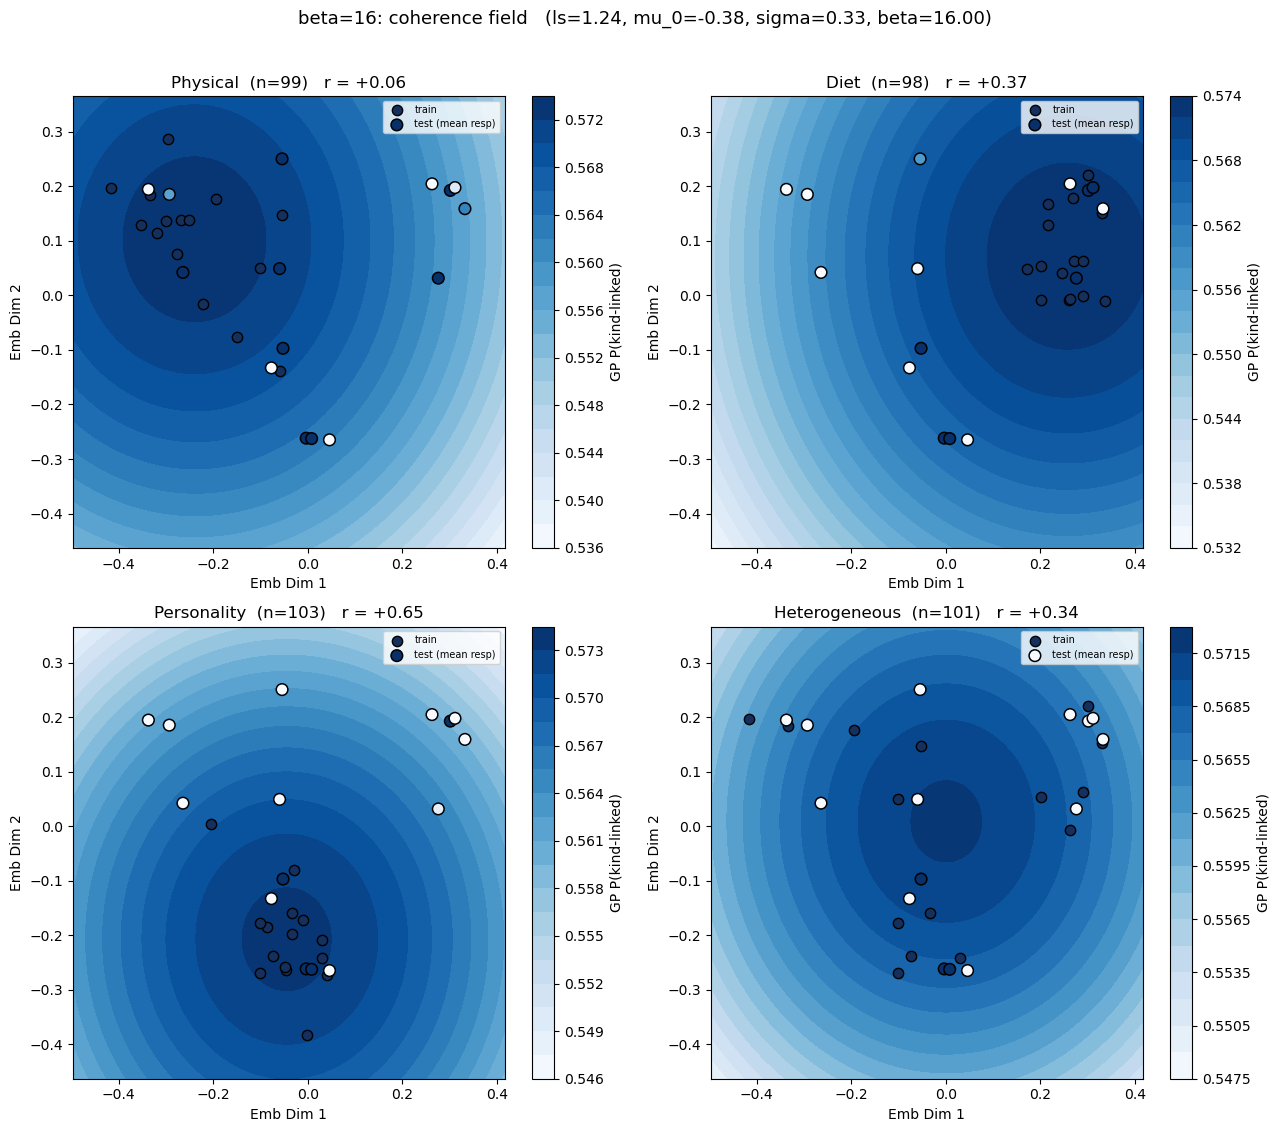

In [6]:
tcolor = {'diet': 'tab:green', 'personality': 'tab:purple', 'physical': 'tab:orange',
          'heterogeneous': 'tab:gray'}
traits = np.array(geom['test_trait'])

# shared 2d grid over all feature points
all_x = np.vstack([np.array(geom['x_test'])] + [np.array(geom['x_train_cond'][c]) for c in inf.CONDITIONS])
pad = 0.08
(x_lo, y_lo), (x_hi, y_hi) = all_x.min(0) - pad, all_x.max(0) + pad
gx, gy = np.meshgrid(np.linspace(x_lo, x_hi, 80), np.linspace(y_lo, y_hi, 80))
X_grid = np.column_stack([gx.ravel(), gy.ravel()])
x_test_np = np.array(geom['x_test'])
N_cond = {c: int(np.array(responses_cond[c]).shape[0]) for c in inf.CONDITIONS}

def plot_fields(name, fit):
    LS, MU, SIG, BETA = median_theta(fit)
    fig, axes = plt.subplots(2, 2, figsize=(13, 11.5))
    for ax, c in zip(axes.ravel(), inf.CONDITIONS):
        field    = inf.gp_coherence_field(geom, c, LS, MU, SIG, X_grid, beta_speaker=BETA).reshape(gx.shape)
        pz1_test = inf.gp_coherence_field(geom, c, LS, MU, SIG, x_test_np, beta_speaker=BETA)
        cs = ax.contourf(gx, gy, field, levels=20, cmap='Blues')
        cb = fig.colorbar(cs, ax=ax); cb.set_label('GP P(kind-linked)')

        x_tr = np.array(geom['x_train_cond'][c])
        ax.scatter(x_tr[:, 0], x_tr[:, 1], s=55, color='#16305e', edgecolor='k', zorder=3, label='train')
        ax.scatter(x_test_np[:, 0], x_test_np[:, 1], s=70, c=emp_cond[c], cmap='Blues', norm=cs.norm,
                   edgecolor='k', linewidth=1.1, zorder=3, label='test (mean resp)')

        if np.ptp(pz1_test) > 1e-3:
            r_txt = f"r = {np.corrcoef(pz1_test, emp_cond[c])[0,1]:+.2f}"
        else:
            r_txt = "field ~ constant (r undefined)"
        ax.set_title(f"{c.capitalize()}  (n={N_cond[c]})   {r_txt}")
        ax.set_xlabel('Emb Dim 1'); ax.set_ylabel('Emb Dim 2')
        ax.legend(fontsize=7, loc='upper right')
    fig.suptitle(f"{name}: coherence field   "
                 f"(ls={LS:.2f}, mu_0={MU:+.2f}, sigma={SIG:.2f}, beta={BETA:.2f})", fontsize=13)
    plt.tight_layout(rect=[0, 0, 1, 0.965])
    plt.show()

for name, fit in fits.items():
    plot_fields(name, fit)
